# UTS Graf Sains Data

| | |
|---|---|
| **Nama** | Jihan Amanda Siagian |
| **NIM** | 23031554184 |
| **Mata Kuliah** | Graf Sains Data |


## Persiapan

In [1]:
import csv
import os
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
from neo4j import GraphDatabase
from sklearn.preprocessing import normalize

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "jihanmanis"
DATA_DIR = "."

In [2]:
# !curl -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
# !unzip ecommerce-dataset.zip

In [3]:
driver = GraphDatabase.driver(URI, auth=(USERNAME, PASSWORD))
driver.verify_connectivity()
print("Terhubung ke Neo4j:", driver.get_server_info().agent)

Terhubung ke Neo4j: Neo4j/2026.10.0


### Impor `events.csv` ke Neo4j


In [4]:
IMPORT_QUERY = '''
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL (v, i, row) {
    WITH v, i, row WHERE row.event = "view"
    MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    UNION
    WITH v, i, row WHERE row.event = "addtocart"
    MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    UNION
    WITH v, i, row WHERE row.event = "transaction"
    MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
}
RETURN count(*)
'''


def import_events(csv_path, batch_size=1000):
    with driver.session(database="neo4j") as session:
        session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
        session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
        total, batch = 0, []
        with open(csv_path, newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                batch.append({
                    "visitorid": int(row["visitorid"]),
                    "itemid": int(row["itemid"]),
                    "timestamp": int(row["timestamp"]),
                    "event": row["event"],
                    "transactionid": row["transactionid"] or "",
                })
                total += 1
                if len(batch) == batch_size:
                    session.execute_write(lambda tx: tx.run(IMPORT_QUERY, batch=batch).consume())
                    batch = []
        if batch:
            session.execute_write(lambda tx: tx.run(IMPORT_QUERY, batch=batch).consume())
    return total


with driver.session(database="neo4j") as session:
    n_visitor = session.run("MATCH (v:Visitor) RETURN count(v) AS n").single()["n"]

if n_visitor > 0:
    print(f"Database sudah berisi {n_visitor:,} Visitor, impor dilewati.")
else:
    print(f"Baris diimpor: {import_events(os.path.join(DATA_DIR, 'events.csv')):,}")

Database sudah berisi 1,407,580 Visitor, impor dilewati.


# 2.1 Wrangling dan EDA

## 1. Periode waktu

Data RetailRocket berada di rentang 3 Mei – 18 September 2015. Periode yang dipakai:

| Fold | Periode |
|---|---|
| P1 (training) | 25/05/2015 – 13/08/2015 |
| P2 (testing) | 14/08/2015 – 03/09/2015 |

P1 dipakai untuk membangun VSM, similarity, dan KNN. P2 dipakai sebagai ground truth evaluasi.
Bobot interaksi: `view` = 1, `addtocart` = 3, `transaction` = 5.

In [5]:
P1_START = pd.Timestamp("2015-05-25 00:00:00", tz="UTC")
P1_END = pd.Timestamp("2015-08-13 23:59:59.999", tz="UTC")
P2_START = pd.Timestamp("2015-08-14 00:00:00", tz="UTC")
P2_END = pd.Timestamp("2015-09-03 23:59:59.999", tz="UTC")

# timestamp di events.csv dan Neo4j berupa epoch milidetik
to_ms = lambda ts: int(ts.timestamp() * 1000)
P1_MS = (to_ms(P1_START), to_ms(P1_END))
P2_MS = (to_ms(P2_START), to_ms(P2_END))

EVENT_WEIGHT = {"view": 1, "addtocart": 3, "transaction": 5}

pd.DataFrame(
    {"mulai": [P1_START, P2_START], "selesai": [P1_END, P2_END],
     "mulai_ms": [P1_MS[0], P2_MS[0]], "selesai_ms": [P1_MS[1], P2_MS[1]]},
    index=["P1", "P2"],
)

,mulai,selesai,mulai_ms,selesai_ms
P1,2015-05-25 00:00:00+00:00,2015-08-13 23:59:59.999000+00:00,1432512000000,1439510399999
P2,2015-08-14 00:00:00+00:00,2015-09-03 23:59:59.999000+00:00,1439510400000,1441324799999


## 2. Filter timestamp dan simpan ke CSV

Baris duplikat (visitor, item, event, dan timestamp sama) dibuang karena di Neo4j baris seperti itu sudah digabung oleh `MERGE`.

In [6]:
events = pd.read_csv(os.path.join(DATA_DIR, "events.csv"))

in_p1 = events["timestamp"].between(*P1_MS)
in_p2 = events["timestamp"].between(*P2_MS)

filtered = events[in_p1 | in_p2].copy()
filtered["fold"] = np.where(in_p1[in_p1 | in_p2], "P1", "P2")
filtered["weight"] = filtered["event"].map(EVENT_WEIGHT)
filtered["event_time"] = pd.to_datetime(filtered["timestamp"], unit="ms", utc=True)
filtered = (
    filtered.drop_duplicates(["visitorid", "itemid", "event", "timestamp"])
    .sort_values("timestamp")
    .reset_index(drop=True)
)

FILTERED_CSV = "events_filtered_20150525_20150903.csv"
filtered.to_csv(FILTERED_CSV, index=False)

print(f"events.csv     : {len(events):,} baris")
print(f"{FILTERED_CSV}: {len(filtered):,} baris\n")
print(filtered.groupby("fold").agg(
    interaksi=("event", "size"),
    visitor=("visitorid", "nunique"),
    item=("itemid", "nunique"),
    awal=("event_time", "min"),
    akhir=("event_time", "max"),
))
print()
print(pd.crosstab(filtered["fold"], filtered["event"]))

events.csv     : 2,756,101 baris
events_filtered_20150525_20150903.csv: 2,056,946 baris



      interaksi  visitor    item                             awal  \
fold                                                                
P1      1685016   871840  190368 2015-05-25 00:00:00.788000+00:00   
P2       371930   210644   92238 2015-08-14 00:00:00.927000+00:00   

                                akhir  
fold                                   
P1   2015-08-13 23:59:56.427000+00:00  
P2   2015-09-03 23:59:57.541000+00:00  



event  addtocart  transaction     view
fold                                  
P1         42021        13878  1629117
P2          9797         3182   358951


## 3. Komposisi subgraph

Filter yang sama diterapkan di Neo4j: relasi yang timestamp-nya masuk P1/P2 diberi properti `fold` dan `weight`.
Subgraph adalah semua relasi yang punya `fold` beserta simpul di kedua ujungnya.

```cypher
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
CALL (r) {
  SET r.fold = CASE
        WHEN r.timestamp >= $p1_start AND r.timestamp <= $p1_end THEN 'P1'
        WHEN r.timestamp >= $p2_start AND r.timestamp <= $p2_end THEN 'P2'
        ELSE null END,
      r.weight = CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END
} IN TRANSACTIONS OF 50000 ROWS
```

`CASE ... ELSE null` menghapus `fold` dari relasi di luar periode. `IN TRANSACTIONS OF 50000 ROWS` memecah update
menjadi beberapa transaksi supaya tidak kehabisan memori.

In [7]:
TAG_QUERY = '''
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
CALL (r) {
  SET r.fold = CASE
        WHEN r.timestamp >= $p1_start AND r.timestamp <= $p1_end THEN 'P1'
        WHEN r.timestamp >= $p2_start AND r.timestamp <= $p2_end THEN 'P2'
        ELSE null END,
      r.weight = CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 ELSE 5 END
} IN TRANSACTIONS OF 50000 ROWS
'''

t0 = time.time()
# CALL ... IN TRANSACTIONS harus lewat auto-commit transaction (session.run)
with driver.session(database="neo4j") as session:
    session.run(TAG_QUERY, p1_start=P1_MS[0], p1_end=P1_MS[1], p2_start=P2_MS[0], p2_end=P2_MS[1]).consume()
print(f"Selesai dalam {time.time() - t0:.1f} detik")

Selesai dalam 33.2 detik


Query komposisi:

```cypher
// jenis dan jumlah simpul
MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]-()
WHERE r.fold IS NOT NULL
WITH DISTINCT n
RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah

// simpul dan relasi per fold
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.fold IS NOT NULL
RETURN r.fold AS fold, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS relasi

// relasi per jenis per fold
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
WHERE r.fold IS NOT NULL
RETURN r.fold AS fold, type(r) AS jenis_relasi, count(*) AS jumlah
```

Query pertama mengambil semua simpul yang terhubung ke relasi bertanda `fold`. `WITH DISTINCT n` mencegah simpul
dihitung berulang, lalu hasilnya dikelompokkan per label. Query kedua menghitung visitor dan item unik di setiap fold
dengan `count(DISTINCT ...)`. Query ketiga mengelompokkan relasi berdasarkan `type(r)`.

In [8]:
COMPOSITION_QUERIES = {
    "Jenis simpul": '''
        MATCH (n)-[r:VIEWED|ADDED_TO_CART|BOUGHT]-()
        WHERE r.fold IS NOT NULL
        WITH DISTINCT n
        RETURN labels(n)[0] AS jenis_simpul, count(*) AS jumlah
        ORDER BY jumlah DESC''',
    "Simpul dan relasi per fold": '''
        MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
        WHERE r.fold IS NOT NULL
        RETURN r.fold AS fold, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS relasi
        ORDER BY fold''',
    "Relasi per jenis": '''
        MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
        WHERE r.fold IS NOT NULL
        RETURN r.fold AS fold, type(r) AS jenis_relasi, count(*) AS jumlah
        ORDER BY fold, jumlah DESC''',
}

with driver.session(database="neo4j") as session:
    for title, query in COMPOSITION_QUERIES.items():
        print(f"== {title} ==")
        print(pd.DataFrame(session.run(query).data()).to_string(index=False), "\n")

print(f"Pembanding dari CSV: visitor = {filtered['visitorid'].nunique():,}, item = {filtered['itemid'].nunique():,}")

== Jenis simpul ==


jenis_simpul  jumlah
     Visitor 1065669
        Item  208339 

== Simpul dan relasi per fold ==


fold  visitor   item  relasi
  P1   871840 190368 1685016
  P2   210644  92238  371930 

== Relasi per jenis ==


fold  jenis_relasi  jumlah
  P1        VIEWED 1629117
  P1 ADDED_TO_CART   42021
  P1        BOUGHT   13878
  P2        VIEWED  358951
  P2 ADDED_TO_CART    9797
  P2        BOUGHT    3182 

Pembanding dari CSV: visitor = 1,065,669, item = 208,339


## 4. VSM untuk User (Visitor)

Setiap visitor menjadi vektor dengan dimensi sebanyak item di P1. Isi vektornya adalah total bobot interaksi
visitor terhadap tiap item:

$$\vec{u} = (w_{u,1}, w_{u,2}, \dots, w_{u,|I|})$$

Matriksnya disimpan sebagai sparse CSR karena versi dense-nya tidak muat di memori. Proyeksi User adalah graf
User–User: dua visitor terhubung kalau pernah menyentuh item yang sama, dengan bobot jumlah item bersama ($BB^\top$, $B$ = matriks biner).

In [9]:
train = filtered[filtered["fold"] == "P1"]
test = filtered[filtered["fold"] == "P2"]

ui = train.groupby(["visitorid", "itemid"], as_index=False)["weight"].sum()
user_index = pd.Index(np.sort(ui["visitorid"].unique()), name="visitorid")
item_index = pd.Index(np.sort(ui["itemid"].unique()), name="itemid")

# X: matriks User x Item, B: versi biner untuk proyeksi
X = sp.csr_matrix(
    (ui["weight"].astype(np.float32),
     (user_index.get_indexer(ui["visitorid"]), item_index.get_indexer(ui["itemid"]))),
    shape=(len(user_index), len(item_index)),
)
B = X.copy()
B.data[:] = 1


def vsm_profile(M, name):
    nnz = M.getnnz(axis=1)
    return pd.Series({
        "jumlah vektor": M.shape[0],
        "dimensi vektor": M.shape[1],
        "shape": M.shape,
        "elemen non-zero": M.nnz,
        "density": M.nnz / (M.shape[0] * M.shape[1]),
        "rata-rata non-zero / vektor": nnz.mean(),
        "median non-zero / vektor": np.median(nnz),
        "maks non-zero / vektor": nnz.max(),
        "vektor dengan 1 non-zero (%)": 100 * (nnz == 1).mean(),
        "memori sparse (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "memori jika dense (GB)": M.shape[0] * M.shape[1] * 4 / 1e9,
    }, name=name)


def projection(Bin):
    t0 = time.time()
    P = (Bin @ Bin.T).tocsr()
    P.setdiag(0)
    P.eliminate_zeros()
    elapsed = time.time() - t0
    deg = P.getnnz(axis=1)
    n = P.shape[0]
    stats = pd.Series({
        "simpul proyeksi": n,
        "simpul terisolasi (%)": 100 * (deg == 0).mean(),
        "edge proyeksi": P.nnz // 2,
        "rata-rata degree": deg.mean(),
        "density proyeksi": P.nnz / (n * (n - 1)),
        "memori proyeksi (MB)": (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6,
        "waktu hitung (detik)": elapsed,
    })
    return P, stats


def plot_ego(P, labels, center, prefix, title, ax, max_neighbors=25):
    row = P.getrow(center)
    neighbors = row.indices[np.argsort(-row.data, kind="stable")[:max_neighbors]]
    nodes = np.r_[center, neighbors]
    G = nx.from_scipy_sparse_array(P[nodes][:, nodes])
    G = nx.relabel_nodes(G, {k: f"{prefix}{labels[n]}" for k, n in enumerate(nodes)})
    pos = nx.spring_layout(G, seed=42, weight=None)
    center_name = f"{prefix}{labels[center]}"
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#bbbbbb",
                           width=[0.4 + 0.6 * np.log1p(d["weight"]) for _, _, d in G.edges(data=True)])
    nx.draw_networkx_nodes(G, pos, ax=ax,
                           node_size=[500 if n == center_name else 160 for n in G],
                           node_color=["#d62728" if n == center_name else "#1f77b4" for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    ax.set_title(title)
    ax.axis("off")
    return G


user_profile = vsm_profile(X, "VSM User")
print(user_profile.to_string())

print("\nContoh 5 vektor User (elemen non-zero):")
for r in range(5):
    row = X.getrow(r)
    print(f"  U{user_index[r]}: {dict(zip(item_index[row.indices].tolist(), row.data.astype(int).tolist()))}")

jumlah vektor                             871840
dimensi vektor                            190368
shape                           (871840, 190368)
elemen non-zero                          1313544
density                                 0.000008
rata-rata non-zero / vektor             1.506634
median non-zero / vektor                     1.0
maks non-zero / vektor                      3028
vektor dengan 1 non-zero (%)           80.317604
memori sparse (MB)                     13.995716
memori jika dense (GB)                663.881748

Contoh 5 vektor User (elemen non-zero):
  U1: {72028: 1}
  U2: {216305: 2, 259884: 1, 325215: 3, 342816: 2}
  U3: {385090: 1}
  U5: {61396: 1}
  U8: {434230: 1}


Proyeksi User-User:
simpul proyeksi          8.718400e+05
simpul terisolasi (%)    5.320242e+00
edge proyeksi            3.609301e+07
rata-rata degree         8.279732e+01
density proyeksi         9.496859e-05
memori proyeksi (MB)     5.809755e+02
waktu hitung (detik)     2.908688e+00


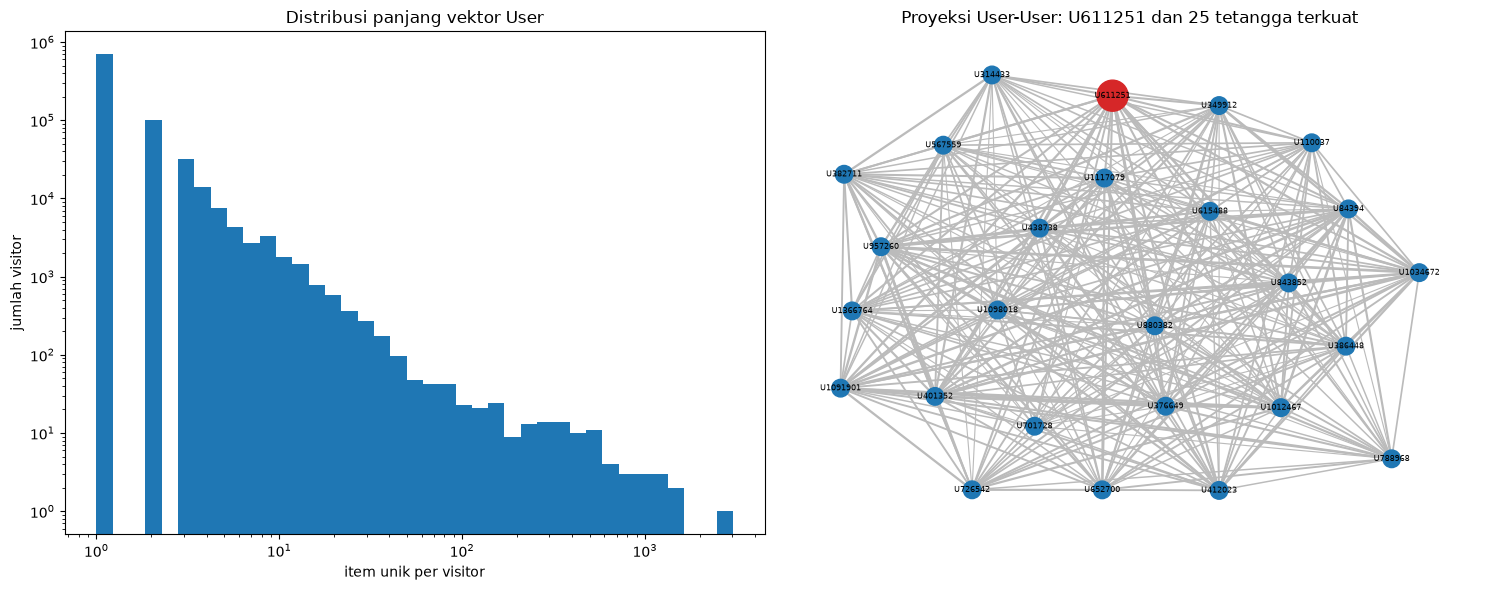

In [10]:
P_user, user_proj_stats = projection(B)
print("Proyeksi User-User:")
print(user_proj_stats.to_string())

# pusat plot: visitor dengan tetangga terbanyak di antara visitor yang riwayatnya <= 20 item (bukan bot)
items_per_user = X.getnnz(axis=1)
candidates = np.where(items_per_user <= 20)[0]
center_user = candidates[np.argmax(P_user.getnnz(axis=1)[candidates])]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].hist(items_per_user, bins=np.logspace(0, np.log10(items_per_user.max() + 1), 40), color="#1f77b4")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("item unik per visitor")
axes[0].set_ylabel("jumlah visitor")
axes[0].set_title("Distribusi panjang vektor User")
G_user_plot = plot_ego(P_user, user_index, center_user, "U",
                       f"Proyeksi User-User: U{user_index[center_user]} dan 25 tetangga terkuat", axes[1])
plt.tight_layout()
plt.show()

VSM User terdiri dari 871.840 vektor berdimensi 190.368 dengan density sekitar 8 × 10⁻⁶. Sekitar 80% visitor hanya
punya satu elemen non-zero, sementara segelintir visitor menyentuh ribuan item (maksimum 3.028, kemungkinan bot).
Proyeksi User–User menghasilkan 36,1 juta edge, tetapi banyak di antaranya muncul hanya karena dua visitor kebetulan
membuka satu item populer yang sama.

## 5. VSM untuk Item

Vektor item adalah transpos dari VSM User, dengan dimensi sebanyak visitor di P1:

$$\vec{i} = (w_{1,i}, w_{2,i}, \dots, w_{|U|,i})$$

Proyeksi Item adalah graf Item–Item: dua item terhubung kalau pernah disentuh visitor yang sama ($B^\top B$).

In [11]:
X_item = X.T.tocsr()
B_item = B.T.tocsr()

item_profile = vsm_profile(X_item, "VSM Item")
print(item_profile.to_string())

print("\nContoh 5 vektor Item (elemen non-zero, maks. 8 ditampilkan):")
for r in range(5):
    row = X_item.getrow(r)
    pairs = list(zip(user_index[row.indices].tolist(), row.data.astype(int).tolist()))
    print(f"  I{item_index[r]}: {dict(pairs[:8])}{' ...' if row.nnz > 8 else ''}")

jumlah vektor                             190368
dimensi vektor                            871840
shape                           (190368, 871840)
elemen non-zero                          1313544
density                                 0.000008
rata-rata non-zero / vektor             6.900025
median non-zero / vektor                     2.0
maks non-zero / vektor                      1846
vektor dengan 1 non-zero (%)           38.450265
memori sparse (MB)                     11.269828
memori jika dense (GB)                663.881748

Contoh 5 vektor Item (elemen non-zero, maks. 8 ditampilkan):
  I4: {1042455: 1}
  I6: {13953: 1, 175267: 1, 183491: 1, 316532: 1, 360541: 1, 496704: 1, 539918: 1, 667886: 1} ...
  I9: {949658: 1}
  I15: {88808: 1, 232847: 1, 633965: 1, 724401: 2, 825021: 1, 863219: 1, 960459: 1, 989647: 2} ...
  I16: {101249: 1, 271241: 1, 280725: 1, 286722: 1, 375506: 1, 534240: 1, 550789: 1, 572889: 1} ...


Proyeksi Item-Item:
simpul proyeksi          1.903680e+05
simpul terisolasi (%)    3.757197e+01
edge proyeksi            1.703803e+07
rata-rata degree         1.790010e+02
density proyeksi         9.402940e-04
memori proyeksi (MB)     2.733699e+02
waktu hitung (detik)     9.727454e-01


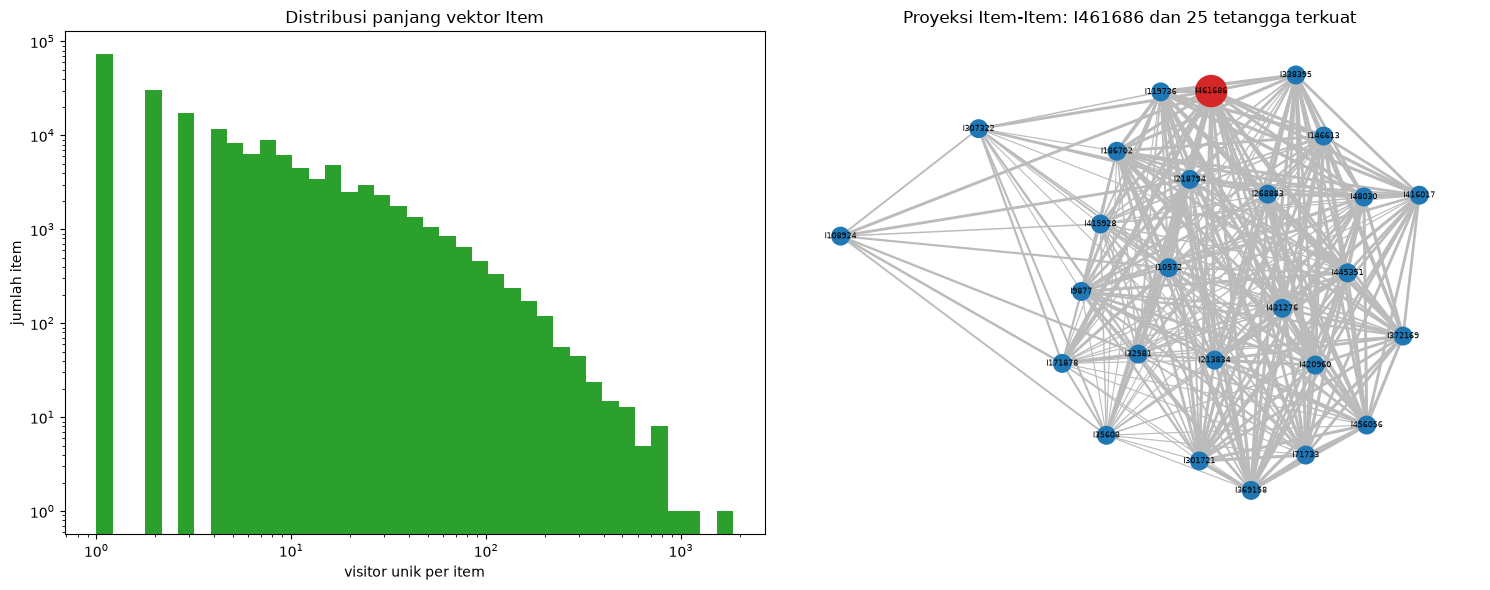

In [12]:
P_item, item_proj_stats = projection(B_item)
print("Proyeksi Item-Item:")
print(item_proj_stats.to_string())

# item acuan untuk no. 5, 7, dan 8: item dengan total bobot interaksi terbesar di P1
ref_pos = int(np.asarray(X_item.sum(axis=1)).ravel().argmax())
REF_ITEM = int(item_index[ref_pos])

users_per_item = X_item.getnnz(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].hist(users_per_item, bins=np.logspace(0, np.log10(users_per_item.max() + 1), 40), color="#2ca02c")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("visitor unik per item")
axes[0].set_ylabel("jumlah item")
axes[0].set_title("Distribusi panjang vektor Item")
G_item_plot = plot_ego(P_item, item_index, ref_pos, "I",
                       f"Proyeksi Item-Item: I{REF_ITEM} dan 25 tetangga terkuat", axes[1])
plt.tight_layout()
plt.show()

VSM Item terdiri dari 190.368 vektor berdimensi 871.840. Jumlah elemen non-zero-nya sama dengan VSM User karena
matriksnya hanya ditranspos, tetapi tersebar di vektor yang jauh lebih sedikit: rata-rata 6,9 visitor per item, dan
hanya 38% item yang dibuka satu visitor. Pada plot, tetangga item acuan juga saling terhubung dan membentuk klaster produk.

## 6. Perbandingan proyeksi

In [13]:
pd.concat([
    pd.concat([user_profile, user_proj_stats]).rename("Proyeksi User"),
    pd.concat([item_profile, item_proj_stats]).rename("Proyeksi Item"),
], axis=1)

,Proyeksi User,Proyeksi Item
jumlah vektor,871840,190368
dimensi vektor,190368,871840
shape,"(871840, 190368)","(190368, 871840)"
elemen non-zero,1313544,1313544
density,0.000008,0.000008
rata-rata non-zero / vektor,1.506634,6.900025
median non-zero / vektor,1.0,2.0
maks non-zero / vektor,3028,1846
vektor dengan 1 non-zero (%),80.317604,38.450265
memori sparse (MB),13.995716,11.269828


Proyeksi Item lebih baik.

**Efisiensi.** Simpulnya 4,6 kali lebih sedikit (190 ribu vs 872 ribu) dan edge-nya kurang dari setengah (17,0 juta
vs 36,1 juta). Memori dan waktu hitungnya juga lebih kecil (273 MB vs 581 MB, 1,0 detik vs 2,9 detik). Similarity
antar-item cukup dihitung sekali untuk semua user. Sebaliknya, populasi visitor terus berganti: dari 871 ribu visitor
di P1, hanya sekitar 16,8 ribu yang muncul lagi di P2.

**Efektivitas.** Vektor item lebih padat (rata-rata 6,9 vs 1,5 non-zero). Karena 80% vektor user hanya berisi satu
elemen, cosine similarity antar-user hampir selalu bernilai 0 atau 1 sehingga kurang informatif. Proyeksi User memang
punya lebih sedikit simpul terisolasi (5% vs 38%), tetapi koneksinya kebanyakan hanya berasal dari satu item populer
yang sama. Simpul item yang terisolasi adalah item yang hanya dibuka satu visitor, sedangkan sekitar 119 ribu item
lainnya punya tetangga dengan bobot co-occurrence yang lebih bermakna.

Karena itu, no. 7 dan bagian Analytics memakai proyeksi Item.

## 7. Similarity pada proyeksi Item

Similarity antar-item dihitung dengan cosine similarity pada vektor item berbobot:

$$\text{sim}(a,b) = \frac{\sum_u w_{u,a}\,w_{u,b}}{\sqrt{\sum_u w_{u,a}^2}\,\sqrt{\sum_u w_{u,b}^2}}$$

Setelah tiap vektor dinormalisasi L2, seluruh matriks similarity didapat dari satu perkalian sparse
$S = \hat{X}_{item}\hat{X}_{item}^\top$. Record acuan yang dipakai adalah item dengan total bobot interaksi terbesar di P1.

In [14]:
X_item_norm = normalize(X_item, norm="l2", axis=1)
S = (X_item_norm @ X_item_norm.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()
print(f"Matriks similarity: shape {S.shape}, {S.nnz // 2:,} pasangan non-zero")


def top_similar(pos, k=5):
    row = S.getrow(pos)
    # skor menurun, itemId menaik kalau skornya sama (sama dengan ORDER BY di Cypher)
    order = np.lexsort((item_index[row.indices], -row.data))[:k]
    return pd.DataFrame({"itemId": item_index[row.indices[order]], "similarity": row.data[order].astype(float)})


print(f"Item acuan: {REF_ITEM} ({users_per_item[ref_pos]} visitor unik di P1)")
top5_python = top_similar(ref_pos)
top5_python.index = np.arange(1, len(top5_python) + 1)
top5_python

Matriks similarity: shape (190368, 190368), 17,038,027 pasangan non-zero
Item acuan: 461686 (760 visitor unik di P1)


,itemId,similarity
1,171878,0.390812
2,218794,0.389686
3,32581,0.359416
4,10935,0.260603
5,14656,0.260603


### 7(a). CYPHER 5 record dengan similarity tertinggi

Cosine similarity yang sama bisa dihitung langsung dari graf di Neo4j:

```cypher
MATCH (ref:Item {itemId: $ref})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WHERE r.fold = 'P1'
WITH ref, v, sum(r.weight) AS wa
WITH ref, collect({v: v, wa: wa}) AS vecA, sqrt(sum(wa * wa)) AS normA
UNWIND vecA AS a
WITH ref, normA, a.v AS v, a.wa AS wa
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE r2.fold = 'P1' AND other <> ref
WITH ref, normA, other, v, wa, sum(r2.weight) AS wb
WITH ref, normA, other, sum(wa * wb) AS dot
CALL (other) {
  MATCH (other)<-[r3:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
  WHERE r3.fold = 'P1'
  WITH u, sum(r3.weight) AS wb
  RETURN sqrt(sum(wb * wb)) AS normB
}
RETURN ref.itemId AS source, other.itemId AS target, dot / (normA * normB) AS similarity
ORDER BY similarity DESC, target ASC
LIMIT 5
```

Alurnya:
1. Bobot interaksi tiap visitor ke item acuan dijumlahkan menjadi $w_{u,ref}$, lalu dihitung `normA`.
2. Dari visitor yang sama, telusuri item lain di P1. `sum(wa * wb)` menghasilkan dot product.
3. Subquery `CALL (other)` menghitung norma tiap item kandidat. Skor akhirnya `dot / (normA * normB)`.

In [15]:
COSINE_TOP5_CYPHER = '''
MATCH (ref:Item {itemId: $ref})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WHERE r.fold = 'P1'
WITH ref, v, sum(r.weight) AS wa
WITH ref, collect({v: v, wa: wa}) AS vecA, sqrt(sum(wa * wa)) AS normA
UNWIND vecA AS a
WITH ref, normA, a.v AS v, a.wa AS wa
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE r2.fold = 'P1' AND other <> ref
WITH ref, normA, other, v, wa, sum(r2.weight) AS wb
WITH ref, normA, other, sum(wa * wb) AS dot
CALL (other) {
  MATCH (other)<-[r3:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
  WHERE r3.fold = 'P1'
  WITH u, sum(r3.weight) AS wb
  RETURN sqrt(sum(wb * wb)) AS normB
}
RETURN ref.itemId AS source, other.itemId AS target, dot / (normA * normB) AS similarity
ORDER BY similarity DESC, target ASC
LIMIT 5
'''

with driver.session(database="neo4j") as session:
    top5_cypher = pd.DataFrame(session.run(COSINE_TOP5_CYPHER, ref=REF_ITEM).data())
top5_cypher.index = np.arange(1, len(top5_cypher) + 1)

same = (np.array_equal(top5_cypher["target"].to_numpy(), top5_python["itemId"].to_numpy())
        and np.allclose(top5_cypher["similarity"], top5_python["similarity"], atol=1e-5))
print("Sama dengan hasil Python:", same)
top5_cypher

Sama dengan hasil Python: True


,source,target,similarity
1,461686,171878,0.390812
2,461686,218794,0.389686
3,461686,32581,0.359416
4,461686,10935,0.260603
5,461686,14656,0.260603


### 7(b). Menulis similarity ke graf

Hasil similarity disimpan sebagai relasi `(:Item)-[:SIMILAR_TO {score, method, fold}]->(:Item)`.
Relasi `SIMILAR_TO` yang lama dihapus dulu agar sel ini bisa dijalankan ulang. Kondisi graf sebelum penulisan
juga disimpan untuk no. 8.

```cypher
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.target})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.similarity, s.method = 'cosine', s.fold = 'P1'
```

```cypher
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS source, b.itemId AS target, s.score AS similarity, s.method AS method, s.fold AS fold
ORDER BY s.score DESC, target ASC
```

In [16]:
TARGETS = top5_python["itemId"].astype(int).tolist()

# item acuan, 5 item target, maks. 3 visitor penghubung per target, dan SIMILAR_TO jika sudah ada
NEIGHBORHOOD_CYPHER = '''
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN $targets
WITH ref, o, v, r1 ORDER BY v.visitorId
WITH ref, o, collect({v: v, r1: r1})[0..3] AS bridges
UNWIND bridges AS b
RETURN 'Visitor' AS src_label, b.v.visitorId AS src, type(b.r1) AS rel, 'Item' AS dst_label, ref.itemId AS dst, null AS score
UNION
MATCH (ref:Item {itemId: $ref})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN $targets
WITH o, v, r2 ORDER BY v.visitorId
WITH o, collect({v: v, r2: r2})[0..3] AS bridges
UNWIND bridges AS b
RETURN 'Visitor' AS src_label, b.v.visitorId AS src, type(b.r2) AS rel, 'Item' AS dst_label, o.itemId AS dst, null AS score
UNION
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN 'Item' AS src_label, a.itemId AS src, 'SIMILAR_TO' AS rel, 'Item' AS dst_label, b.itemId AS dst, s.score AS score
'''
COUNT_SIMILAR_CYPHER = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS total"
WRITE_SIMILAR_CYPHER = '''
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.target})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.similarity, s.method = 'cosine', s.fold = 'P1'
'''
READ_SIMILAR_CYPHER = '''
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS source, b.itemId AS target, s.score AS similarity, s.method AS method, s.fold AS fold
ORDER BY s.score DESC, target ASC
'''

rows = [{"target": int(t), "similarity": float(s)} for t, s in zip(top5_python["itemId"], top5_python["similarity"])]

# notifikasi UNRECOGNIZED dimatikan karena tipe SIMILAR_TO belum ada sebelum ditulis
with driver.session(database="neo4j", notifications_disabled_classifications=["UNRECOGNIZED"]) as session:
    session.run("MATCH ()-[s:SIMILAR_TO]->() DELETE s").consume()

    before_count = session.run(COUNT_SIMILAR_CYPHER).single()["total"]
    before_edges = pd.DataFrame(session.run(NEIGHBORHOOD_CYPHER, ref=REF_ITEM, targets=TARGETS).data())

    session.run(WRITE_SIMILAR_CYPHER, ref=REF_ITEM, rows=rows).consume()

    after_count = session.run(COUNT_SIMILAR_CYPHER).single()["total"]
    after_edges = pd.DataFrame(session.run(NEIGHBORHOOD_CYPHER, ref=REF_ITEM, targets=TARGETS).data())
    similar_written = pd.DataFrame(session.run(READ_SIMILAR_CYPHER, ref=REF_ITEM).data())

print(f"SIMILAR_TO sebelum: {before_count}, sesudah: {after_count}\n")
similar_written

SIMILAR_TO sebelum: 0, sesudah: 5



,source,target,similarity,method,fold
0,461686,171878,0.390812,cosine,P1
1,461686,218794,0.389686,cosine,P1
2,461686,32581,0.359416,cosine,P1
3,461686,10935,0.260603,cosine,P1
4,461686,14656,0.260603,cosine,P1


## 8. Graf sebelum dan sesudah similarity

Query yang sama dijalankan sebelum dan sesudah penulisan `SIMILAR_TO`. Bagian pertama dan kedua `UNION` mengambil
visitor yang menghubungkan item acuan dengan kelima item target (maks. 3 visitor per target). Bagian ketiga hanya
mengembalikan baris kalau `SIMILAR_TO` sudah ada.

```cypher
MATCH (ref:Item {itemId: $ref})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN $targets
...
UNION
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN 'Item' AS src_label, a.itemId AS src, 'SIMILAR_TO' AS rel, 'Item' AS dst_label, b.itemId AS dst, s.score AS score
```

Versi untuk Neo4j Browser (http://localhost:7474) dicetak di sel berikut dengan nilai yang sebenarnya.

// Neo4j Browser
MATCH p = (ref:Item {itemId: 461686})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN [171878, 218794, 32581, 10935, 14656]
RETURN p LIMIT 30
UNION
MATCH p = (:Item {itemId: 461686})-[:SIMILAR_TO]->(:Item)
RETURN p

Sebelum:
src_label     src           rel dst_label    dst score
  Visitor    2951        VIEWED      Item 461686  None
  Visitor   22084        VIEWED      Item 461686  None
  Visitor   15239        VIEWED      Item 461686  None
  Visitor   23087        VIEWED      Item 461686  None
  Visitor 1150086        VIEWED      Item 461686  None
  Visitor    2951        VIEWED      Item  32581  None
  Visitor   22084        VIEWED      Item  32581  None
  Visitor   22084 ADDED_TO_CART      Item  32581  None
  Visitor   15239        VIEWED      Item 171878  None
  Visitor   22084        VIEWED      Item 218794  None
  Visitor   23087        VIEWED      Item 218794  None
  Visitor 1150086        VIEWED      Item  10935  None
  

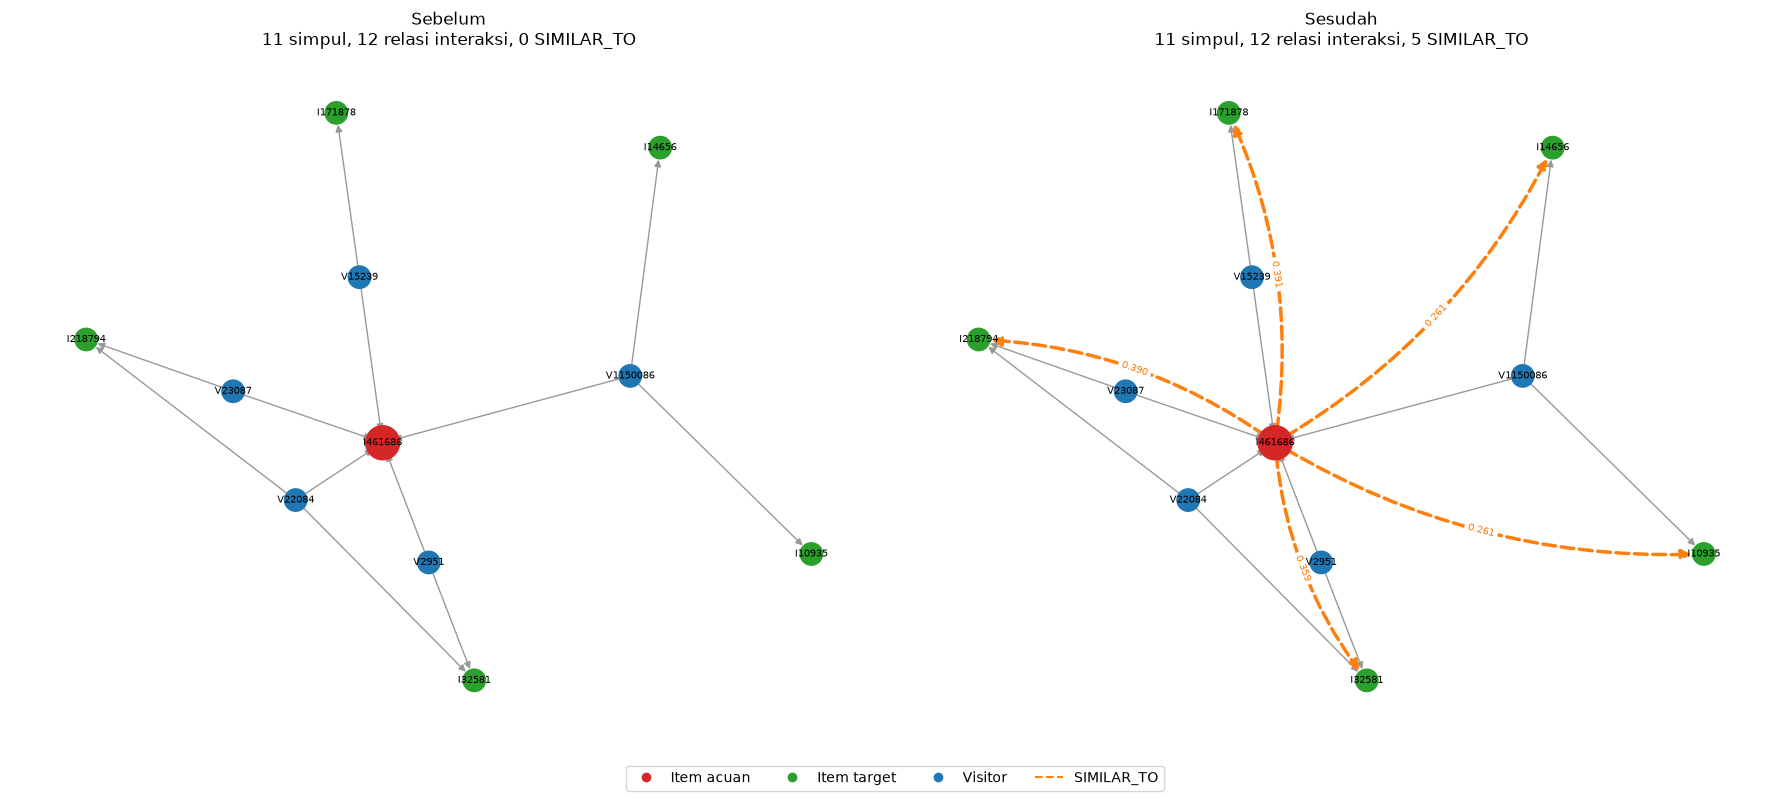

In [17]:
print(f'''// Neo4j Browser
MATCH p = (ref:Item {{itemId: {REF_ITEM}}})<-[r1]-(v:Visitor)-[r2]->(o:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND o.itemId IN {TARGETS}
RETURN p LIMIT 30
UNION
MATCH p = (:Item {{itemId: {REF_ITEM}}})-[:SIMILAR_TO]->(:Item)
RETURN p
''')

print("Sebelum:")
print(before_edges.to_string(index=False))
print("\nTambahan sesudah:")
print(after_edges[after_edges["rel"] == "SIMILAR_TO"].to_string(index=False))


def draw_state(edges, ax, title):
    G = nx.DiGraph()
    for e in edges.itertuples(index=False):
        src, dst = f"{e.src_label[0]}{e.src}", f"{e.dst_label[0]}{e.dst}"
        G.add_node(src, label=e.src_label)
        G.add_node(dst, label=e.dst_label)
        G.add_edge(src, dst, rel=e.rel, score=e.score)
    ref_name = f"I{REF_ITEM}"
    pos = nx.spring_layout(G, seed=7, pos={ref_name: (0, 0)}, fixed=[ref_name])
    colors = ["#d62728" if n == ref_name else "#2ca02c" if G.nodes[n]["label"] == "Item" else "#1f77b4" for n in G]
    inter = [(u, v) for u, v, d in G.edges(data=True) if d["rel"] != "SIMILAR_TO"]
    sim = [(u, v) for u, v, d in G.edges(data=True) if d["rel"] == "SIMILAR_TO"]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=[600 if n == ref_name else 260 for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=inter, edge_color="#999999", arrows=True, arrowsize=10)
    if sim:
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=sim, edge_color="#ff7f0e", width=2.5, style="dashed",
                               arrows=True, arrowsize=14, connectionstyle="arc3,rad=0.15")
        nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=7, font_color="#ff7f0e",
                                     edge_labels={(u, v): f"{G[u][v]['score']:.3f}" for u, v in sim},
                                     connectionstyle="arc3,rad=0.15")
    ax.set_title(f"{title}\n{G.number_of_nodes()} simpul, {len(inter)} relasi interaksi, {len(sim)} SIMILAR_TO")
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(18, 8))
draw_state(before_edges, axes[0], "Sebelum")
draw_state(after_edges, axes[1], "Sesudah")
fig.legend(handles=[
    plt.Line2D([], [], marker="o", ls="", color="#d62728", label="Item acuan"),
    plt.Line2D([], [], marker="o", ls="", color="#2ca02c", label="Item target"),
    plt.Line2D([], [], marker="o", ls="", color="#1f77b4", label="Visitor"),
    plt.Line2D([], [], color="#ff7f0e", ls="--", label="SIMILAR_TO"),
], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

Sebelum similarity dihitung, item acuan dan item target hanya terhubung secara tidak langsung lewat visitor
(`Item <- Visitor -> Item`, 2 hop). Sesudahnya ada relasi `SIMILAR_TO` 1 hop yang menyimpan skornya, sehingga
item mirip bisa langsung diambil dengan `MATCH (:Item {itemId: ...})-[s:SIMILAR_TO]->(rec) RETURN rec ORDER BY s.score DESC`.

# 2.2 Analytics

## 1. Rekomendasi KNN untuk user acak

Cara memilih user:
1. Kandidatnya visitor yang aktif di P1 dan P2 serta punya minimal 5 item unik di P1. Syarat P2 diperlukan supaya
   hasilnya bisa dievaluasi, dan minimal 5 item supaya KNN punya cukup riwayat.
2. Kandidat diurutkan berdasarkan `visitorId`, lalu satu visitor diambil dengan `np.random.default_rng(42)`.
   Karena seed dan urutannya tetap, hasilnya selalu sama.

In [18]:
SEED = 42
MIN_ITEMS_P1 = 5

items_p1 = train.groupby("visitorid")["itemid"].nunique()
pool = np.sort(np.intersect1d(items_p1[items_p1 >= MIN_ITEMS_P1].index, test["visitorid"].unique()))

rng = np.random.default_rng(SEED)
TARGET_USER = int(rng.choice(pool))

print(f"Jumlah kandidat: {len(pool):,} visitor")
print(f"User terpilih: {TARGET_USER}")

history = (
    train[train["visitorid"] == TARGET_USER]
    .groupby("itemid")
    .agg(bobot=("weight", "sum"), event=("event", lambda s: ", ".join(sorted(s.unique()))))
    .sort_values("bobot", ascending=False)
)
print(f"Riwayat P1: {len(history)} item")
history

Jumlah kandidat: 2,099 visitor
User terpilih: 133770
Riwayat P1: 8 item


,bobot,event
itemid,,
268006,4,"addtocart, view"
35002,1,view
205138,1,view
198615,1,view
237524,1,view
304558,1,view
379301,1,view
465582,1,view


### 1(a). Skrip KNN

KNN dijalankan pada proyeksi Item sesuai hasil no. 6:

1. Untuk tiap item $i$ di riwayat user, ambil $k = 5$ tetangga terdekat $N_k(i)$ menurut cosine similarity.
2. Skor kandidat: $\text{score}(j) = \sum_{i \in I_u,\; j \in N_k(i)} w_{u,i}\cdot \text{sim}(i, j)$.
3. Urutkan skor dari yang terbesar. Tiga teratas menjadi item yang diiklankan.

Item yang sudah pernah dilihat tidak dibuang, karena iklan ulang untuk item yang pernah dilihat (*retargeting*)
umum dipakai di e-commerce. Sekitar 36% kandidat memang membuka lagi item lamanya di P2.

In [19]:
def knn_recommend(visitor_id, k=5, n=3):
    user_row = X.getrow(user_index.get_loc(visitor_id))
    scores, sources = {}, {}
    for item_pos, w in zip(user_row.indices, user_row.data):
        neighbors = S.getrow(item_pos)
        order = np.lexsort((item_index[neighbors.indices], -neighbors.data))[:k]
        for nb_pos, sim in zip(neighbors.indices[order], neighbors.data[order]):
            nb_item = int(item_index[nb_pos])
            scores[nb_item] = scores.get(nb_item, 0.0) + float(w) * float(sim)
            sources.setdefault(nb_item, []).append(int(item_index[item_pos]))
    ranking = sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:n]
    return pd.DataFrame(
        [(rank, item, score, sources[item]) for rank, (item, score) in enumerate(ranking, start=1)],
        columns=["rank", "itemId", "score", "tetangga_dari_item"],
    ).set_index("rank")


K = 5
N_ADS = 3
recommendations = knn_recommend(TARGET_USER, k=K, n=N_ADS)

### 1(b). Tiga item yang diiklankan (k = 5)

In [20]:
recommendations["pernah_dilihat_di_P1"] = recommendations["itemId"].isin(history.index)
recommendations

,itemId,score,tetangga_dari_item,pernah_dilihat_di_P1
rank,,,,
1,153874,3.123889,[268006],False
2,319773,2.760262,[268006],False
3,372617,2.651974,[268006],False


## 2. Hit@5 dan NDCG@5

Ground truth adalah item yang disentuh user di P2. Relevansinya biner: $rel_i = 1$ kalau item di posisi $i$ ada di ground truth.

$$\text{Hit@5} = \begin{cases}1 & \text{ada item relevan di 5 posisi teratas}\\0 & \text{tidak ada}\end{cases}$$

$$\text{DCG@5} = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}, \qquad
\text{IDCG@5} = \sum_{i=1}^{\min(|T|,5)} \frac{1}{\log_2(i+1)}, \qquad
\text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

Daftar yang dievaluasi adalah 3 item dari no. 1(b), jadi posisi 4 dan 5 kosong ($rel = 0$).

In [21]:
def hit_at_k(recommended, truth, k=5):
    return int(any(item in truth for item in recommended[:k]))


def ndcg_at_k(recommended, truth, k=5):
    dcg = sum(1 / np.log2(i + 2) for i, item in enumerate(recommended[:k]) if item in truth)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0


ground_truth = set(test.loc[test["visitorid"] == TARGET_USER, "itemid"].astype(int))
recommended = recommendations["itemId"].tolist()

detail = pd.DataFrame({"rank": range(1, 6), "itemId": recommended + [None] * (5 - len(recommended))})
detail["rel"] = detail["itemId"].apply(lambda x: int(x in ground_truth) if x is not None else 0)
detail["1/log2(rank+1)"] = 1 / np.log2(detail["rank"] + 1)
detail["kontribusi DCG"] = detail["rel"] * detail["1/log2(rank+1)"]

HIT5 = hit_at_k(recommended, ground_truth)
NDCG5 = ndcg_at_k(recommended, ground_truth)

print(f"Ground truth P2 ({len(ground_truth)} item): {sorted(ground_truth)}\n")
print(detail.to_string(index=False))
print(f"\nDCG@5  = {detail['kontribusi DCG'].sum():.4f}")
print(f"IDCG@5 = {sum(1 / np.log2(i + 2) for i in range(min(len(ground_truth), 5))):.4f}")
print(f"Hit@5  = {HIT5}")
print(f"NDCG@5 = {NDCG5:.4f}")

Ground truth P2 (2 item): [134751, 343190]

 rank   itemId  rel  1/log2(rank+1)  kontribusi DCG
    1 153874.0    0        1.000000             0.0
    2 319773.0    0        0.630930             0.0
    3 372617.0    0        0.500000             0.0
    4      NaN    0        0.430677             0.0
    5      NaN    0        0.386853             0.0

DCG@5  = 0.0000
IDCG@5 = 1.6309
Hit@5  = 0
NDCG@5 = 0.0000


Sebagai pembanding, metrik yang sama dihitung untuk semua kandidat user:

In [22]:
truth_by_user = test.groupby("visitorid")["itemid"].agg(lambda s: set(s.astype(int)))
pool_metrics = []
for uid in pool:
    recs = knn_recommend(int(uid), k=K, n=N_ADS)["itemId"].tolist()
    pool_metrics.append((hit_at_k(recs, truth_by_user[uid]), ndcg_at_k(recs, truth_by_user[uid])))
pool_metrics = pd.DataFrame(pool_metrics, columns=["Hit@5", "NDCG@5"])
print(f"Rata-rata {len(pool):,} kandidat:")
print(pool_metrics.mean().round(4).to_string())

Rata-rata 2,099 kandidat:
Hit@5     0.0667
NDCG@5    0.0331


User 133770 menyentuh 2 item di P2 (134751 dan 343190), dan keduanya tidak termasuk dalam 3 item yang diiklankan.
Akibatnya Hit@5 = 0 dan NDCG@5 = 0 (DCG = 0, IDCG = 1,6309). Ketiga rekomendasi berasal dari tetangga item 268006,
satu-satunya item yang dimasukkan ke keranjang sehingga bobotnya paling besar.

Hasil ini sejalan dengan rata-rata seluruh kandidat (Hit@5 = 6,7%, NDCG@5 = 0,033). Peluang tepat sasaran memang kecil
karena datanya sangat sparse, fold testing hanya 3 minggu, dan daftar yang dievaluasi hanya berisi 3 item.